##### Import Python packages

In [37]:
!pip install -r ./requirements.txt

In [38]:
import gymnasium as gym 
import torch.nn as nn
from collections import namedtuple, deque
import torch
import os
import torch.optim as optim
import time
import cv2
import numpy as np
from itertools import count
import random
import math
import pickle
import string
import matplotlib.pyplot as plt
import wandb

##### Define image preprocessing step. The image (scenario) is resized, converted to grayscale and normalized to speed up the training process, keeping the necessary information from the scenario, and discarding the ones that are not relevant (such as color).

In [39]:
def image_preprocessing(img):
    img = cv2.resize(img, dsize=(84, 84))
    img = cv2.cvtColor(img, cv2.COLOR_RGB2GRAY) / 255.0
    return img

Define the Car Racing Environment. The wrapper inherits from the default Gymnasium environment, but lets you modify the logic of how the agent will interact with your environment. Exposes an API where you can manipulate the environment, such as no_operation=50, the agent does nothing for 50 steps (ensures redundancy in the training step), skip_frames=3, decides how often the agent makes a decision (the agents applies the same action for 3 consecutive frames of the environment, ensures spped-up in the training process), stack_frames=4, from which the agents gets a sense of motion (direction of movement, speed) by stacking a number of frames together (time frames), each frame is several environmnets steps apart if skip_frames is defined. reset() API function resets the environment to the starting position, step() defines how the environment behaves for the agent.

Define key variables. Change for experiments.

In [40]:
# To be modified 
BATCH_SIZE=256
EPISODES=200
GAMMA=0.9

device = torch.device("cuda" if torch.cuda.is_available() else "cpu")
print(f"Using device: {device}")

Using device: cuda


In [41]:
class CarEnvironment(gym.Wrapper):
    def __init__(self, env, skip_frames=3, stack_frames=4, no_operation=50, **kwargs):
        super().__init__(env, **kwargs)
        self._no_operation = no_operation
        self._skip_frames = skip_frames
        self._stack_frames = stack_frames

    def reset(self):
        observation, info = self.env.reset()

        for i in range(self._no_operation):
            observation, reward, terminated, truncated, info = self.env.step(0)

        observation = image_preprocessing(observation)
        self.stack_state = np.tile(observation, (self._stack_frames, 1, 1))
        return self.stack_state, info

    def step(self, action):
        total_reward = 0
        for i in range(self._skip_frames):
            observation, reward, terminated, truncated, info = self.env.step(action)
            total_reward += reward
            if terminated or truncated:
                break

        observation = image_preprocessing(observation)
        self.stack_state = np.concatenate((self.stack_state[1:], observation[np.newaxis]), axis=0)
        return self.stack_state, total_reward, terminated, truncated, info

Define the Policy (neural network that will need to be trained) based in convolution neural layers. The size of the out_channels is the size of the action space (i.e., 5).

Action space:
* 0 - do nothing
* 1 - steer to the right
* 2 - steer to the left
* 3 - accelerate
* 4 - brake

You are to define your Policy (stacked convolutional layers).

In [42]:
class CNN(nn.Module):
    def __init__(self, in_channels, out_channels, *args, **kwargs):
        super().__init__(*args, **kwargs)

        self._n_features = 64 * 7 * 7
        # output = (channels,height,width)
        # out = (input_size - kernel_size)/(stride_size) + 1 for each CNN layer
        # n_features = channels x height x width, final conv layer
        

        self.conv = nn.Sequential(
            nn.Conv2d(in_channels, 16, kernel_size=8, stride=4),
            nn.ReLU(),

            nn.Conv2d(16, 32, kernel_size=4, stride=2),
            nn.ReLU(),

            nn.Conv2d(32, 64, kernel_size=3, stride=1),
            nn.ReLU(),
        )

        self.fc = nn.Sequential(
            nn.Linear(self._n_features, 256),
            nn.ReLU(),
            nn.Linear(256, out_channels),
        )

    def forward(self, x):
        x = self.conv(x)
        x = x.view(x.size(0), -1)
        x = self.fc(x)
        return x

Define a tuple that codifies a transition with readable field names.

In [43]:
Transition = namedtuple('Transition', ('state', 'action', 'next_state', 'reward'))

Define the Experience Replay (Memory) used for training. The DQN algorithm will sample from the Experience Memory at training time to ensure consistency, remove cross-correlation between the past and future frames, and reduce chances to overfit. Stores transition-type objects. At training time the the transitions batch is chosen randomly (Vanilla Experience Replay Memory).

In [44]:
class ReplayMemory(object):

    def __init__(self, capacity):
        self.memory = deque([], maxlen=capacity)

    def push(self, *args):
        self.memory.append(Transition(*args))

    def sample(self, batch_size):
        return random.sample(self.memory, batch_size)

    def __len__(self):
        return len(self.memory)

Define the DQN algorithm

In [45]:
class DQN:
    def __init__(self, action_space, batch_size=BATCH_SIZE, gamma=GAMMA,
                 eps_start=0.9, eps_end=0.05, eps_decay=1000, lr=0.001):
        self._n_observation = 4
        self._n_actions = 5
        self._action_space = action_space
        self._batch_size = batch_size
        self._gamma = gamma
        self._eps_start = eps_start
        self._eps_end = eps_end
        self._eps_decay = eps_decay
        self._lr = lr
        self._total_steps = 0
        self._evaluate_loss = []

        # Define the neural network to be trained and the target network, each one having the same blueprint
        self.network = CNN(self._n_observation, self._n_actions).to(device)
        self.target_network = CNN(self._n_observation, self._n_actions).to(device)
        self.target_network.load_state_dict(self.network.state_dict())

        self.optimizer = optim.AdamW(self.network.parameters(), lr=self._lr, amsgrad=True)
        # Define the capacity of the Replay Memory
        self._memory = ReplayMemory(10000)

    """
    (1) Exploitation: This function feeds the neural network a state
    and then it selects the action with the highest Q-value. Corresponds to the training phase.
    (2) Evaluation mode: This function feeds the neural network a state
    and then it selects the action with the highest Q'-value. Compares with the target network.
    (3) Exploration mode: It randomly selects an action through sampling
    """

    def select_action(self, state, evaluation_phase=False):

        # Generating a random number for exploration vs exploitation
        sample = random.random()

        # Calculating epsilon threshold 
        eps_threshold = self._eps_end + (self._eps_start - self._eps_end) * math.exp(
            -1. * self._total_steps / self._eps_decay
        )
        self._total_steps += 1

        if evaluation_phase:
            # (2) Evaluation mode
            with torch.no_grad():
                return self.target_network(state).max(1).indices.view(1, 1)
        elif sample > eps_threshold:
            # (1) Exploitation mode 
            with torch.no_grad():
                return self.network(state).max(1).indices.view(1, 1)
        else:
            # (3) Exploration model
            return torch.tensor([[self._action_space.sample()]], device=device, dtype=torch.long)


    def train(self):

        if len(self._memory) < self._batch_size:
            return None

        # Sample from the Replay Memory
        transitions = self._memory.sample(self._batch_size)
        batch = Transition(*zip(*transitions))

        non_final_mask = torch.tensor(
            tuple(map(lambda s: s is not None, batch.next_state)),
            device=device, dtype=torch.bool
        )

        non_final_next_states = [s for s in batch.next_state if s is not None]
        if len(non_final_next_states) > 0:
            non_final_next_states = torch.cat(non_final_next_states)

        state_batch = torch.cat(batch.state)
        action_batch = torch.cat(batch.action)
        reward_batch = torch.cat(batch.reward)

        # Q(s_t, a), 
        state_action_values = self.network(state_batch).gather(1, action_batch)

        # V(s_{t+1}) for non-final states, Q-value of the next state provided by the target network
        next_state_values = torch.zeros(self._batch_size, device=device)
        with torch.no_grad():
            if non_final_mask.any():
                next_state_values[non_final_mask] = self.target_network(non_final_next_states).max(1).values

        # Bellman's equation, with discount factor _gamma
        expected_state_action_values = (next_state_values * self._gamma) + reward_batch

        # Compute the loss function between the Q-value of the network in the current state 
        # and the expected Q-value provided by the Bellman's equation
        criterion = nn.SmoothL1Loss()
        loss = criterion(state_action_values, expected_state_action_values.unsqueeze(1))

        self.optimizer.zero_grad()
        # Save new parameters though backpropagation
        loss.backward()
        torch.nn.utils.clip_grad_value_(self.network.parameters(), 100)
        self.optimizer.step()

        self._evaluate_loss.append(loss.item())
        return loss.item()


    # Utility functions
    def copy_weights(self):
        self.target_network.load_state_dict(self.network.state_dict())

    def get_loss(self):
        return self._evaluate_loss

    def save_model(self, i):
        path = os.path.join(OUTPUT_DIR, f'model_weights_{i}.pth')
        torch.save(self.target_network.state_dict(), path)

    def load_model(self, i):
        path = os.path.join(OUTPUT_DIR, f'model_weights_{i}.pth')
        self.target_network.load_state_dict(torch.load(path, map_location=device))

Define the train logic

In [46]:
def train(episodes=EPISODES, update_target_frequency=5):

    # Initialize Weights & Biases run
    wandb.init(
        project="car-racing-dqn",
        config={
            "episodes": episodes,
            "batch_size": BATCH_SIZE,
            "device": str(device),
            "update_target_frequency": update_target_frequency,
            "gamma": GAMMA,
            "eps_start": 0.9,
            "eps_end": 0.05,
            "eps_decay": 1000,
            "lr": 0.001,
        },
        name=f"dqn_ep{episodes}_bs{BATCH_SIZE}_{device}"
    )
    wandb.define_metric("episode")
    wandb.define_metric("*", step_metric="episode")

    # Variables used for statistics
    episode_duration = []
    average_episode_loss = []
    rewards_per_episode = []

    # Define the Gymnazium Car Racing Environment
    env = gym.make('CarRacing-v3', continuous=False)
    n_actions = env.action_space

    # Initialize the agent
    agent = DQN(n_actions)

    # Log gradients/parameters
    wandb.watch(agent.network, log="all", log_freq=100)

    start_time = time.time()

    # Loop through the total number of episodes
    for episode in range(1, episodes + 1):

        if episode % 10 == 0:
            print(f"{episode} episodes done")

        env = gym.make('CarRacing-v3', continuous=False)
        env = CarEnvironment(env)

        state, info = env.reset()
        state = torch.tensor(state, dtype=torch.float32, device=device).unsqueeze(0)

        episode_total_reward = 0.0
        episode_losses = []

        # Define a continuous count until break occurs (lap terminated or another interruption occurred)
        for t in count():
            action = agent.select_action(state)
            observation, reward, terminated, truncated, _ = env.step(action.item())
            reward = torch.tensor([reward], device=device, dtype=torch.float32)
            episode_total_reward += reward.item()
            done = terminated or truncated

            if terminated:
                next_state = None
                print("Finished the lap successfully!")
                # agent.copy_weights()
            else:
                next_state = torch.tensor(observation, dtype=torch.float32, device=device).unsqueeze(0)

            # Save transition in Replay Memory
            agent._memory.push(state, action, next_state, reward)
            state = next_state

            loss_value = agent.train()
            if loss_value is not None:
                episode_losses.append(loss_value)

            if done:
                current_duration = t + 1
                current_avg_loss = float(np.mean(episode_losses)) if len(episode_losses) > 0 else 0.0

                episode_duration.append(current_duration)
                rewards_per_episode.append(episode_total_reward)
                average_episode_loss.append(current_avg_loss)

                # Log metrics to Weights & Biases for every episode
                wandb.log({
                    "episode": episode,
                    "reward_per_episode": episode_total_reward,
                    "average_loss_per_episode": current_avg_loss,
                    "duration_steps_per_episode": current_duration,
                    "memory_size": len(agent._memory),
                    # epsilon gives insight about exploration and exploitation 
                    #(at the beginning mostly exploration and at the end mostly explotation)
                    "epsilon": agent._eps_end + (agent._eps_start - agent._eps_end) * math.exp(
                        -1. * agent._total_steps / agent._eps_decay 
                    ),
                }, step=episode)

                break

        # Save training statistics every 100 episodes in a pickle file
        if episode % 100 == 0:
            agent.save_model(episode)
            stats_path = os.path.join(OUTPUT_DIR, 'statistics.pkl')
            with open(stats_path, 'wb') as f:
                pickle.dump((episode_duration, rewards_per_episode, average_episode_loss, None), f)

        # Update the target network based on the trained network after #update_target_frequency episodes
        if episode % update_target_frequency == 0:
            agent.copy_weights()

    end_time = time.time()
    training_time_seconds = end_time - start_time

    # Save state of the model every 100 episodes
    agent.save_model(episodes)

    stats_path = os.path.join(OUTPUT_DIR, 'statistics.pkl')
    with open(stats_path, 'wb') as f:
        pickle.dump(
            (episode_duration, rewards_per_episode, average_episode_loss, training_time_seconds),
            f
        )

    print(f"Total training time: {training_time_seconds:.2f} seconds "
        f"({training_time_seconds/60:.2f} minutes)")

    # Create and upload the three plots to Weights & Biases
    x = np.arange(1, len(rewards_per_episode) + 1)

    rewards_plot_path = os.path.join(OUTPUT_DIR, 'wandb_rewards_per_episode.png')
    plt.figure()
    plt.plot(x, rewards_per_episode)
    plt.xlabel("Episode")
    plt.ylabel("Reward")
    plt.title("Rewards for every episode")
    plt.grid(True)
    plt.savefig(rewards_plot_path)
    plt.close()

    loss_plot_path = os.path.join(OUTPUT_DIR, 'wandb_average_loss_per_episode.png')
    plt.figure()
    plt.plot(x, average_episode_loss)
    plt.xlabel("Episode")
    plt.ylabel("Average Loss")
    plt.title("Average loss for every episode")
    plt.grid(True)
    plt.savefig(loss_plot_path)
    plt.close()

    duration_plot_path = os.path.join(OUTPUT_DIR, 'wandb_duration_steps_per_episode.png')
    plt.figure()
    plt.plot(x, episode_duration)
    plt.xlabel("Episode")
    plt.ylabel("Duration in steps")
    plt.title("Duration in steps for every episode")
    plt.grid(True)
    plt.savefig(duration_plot_path)
    plt.close()

    wandb.log({
        "rewards_plot": wandb.Image(rewards_plot_path),
        "average_loss_plot": wandb.Image(loss_plot_path),
        "duration_steps_plot": wandb.Image(duration_plot_path),
        "training_time_seconds": training_time_seconds,
        "training_time_minutes": training_time_seconds / 60.0,
    })

    wandb.summary["final_reward_per_episode"] = rewards_per_episode[-1] if rewards_per_episode else None
    wandb.summary["final_average_loss_per_episode"] = average_episode_loss[-1] if average_episode_loss else None
    wandb.summary["final_duration_steps_per_episode"] = episode_duration[-1] if episode_duration else None
    wandb.summary["episodes"] = episodes
    wandb.summary["batch_size"] = BATCH_SIZE
    wandb.summary["device"] = str(device)

    wandb.finish()


Define simulation helper functions for animation and stastistics

In [47]:
def _animate(imgs, video_name, _return=True):

    if video_name is None:
        video_name = ''.join(random.choice(string.ascii_letters) for i in range(18)) + '.webm'

    height, width, layers = imgs[0].shape
    fourcc = cv2.VideoWriter_fourcc(*'VP90')
    video_path = os.path.join(OUTPUT_DIR, video_name)
    video = cv2.VideoWriter(video_path, fourcc, 10, (width, height))

    for img in imgs:
        img = cv2.cvtColor(img, cv2.COLOR_BGR2RGB)
        video.write(img)
    video.release()

In [48]:
def _plot_statistics(x, y, title, x_axis, y_axis):
    plt.plot(x, y)
    plt.xlabel(x_axis)
    plt.ylabel(y_axis)
    plt.title(title)
    plt.grid(True)
    plt.savefig(os.path.join(OUTPUT_DIR, f'{title}.png'))
    plt.show()

In [49]:
def _to_cpu_array(x):
    # Convert tensors to a NumPy array for inference
    if torch.is_tensor(x):
        return x.detach().cpu().numpy()
    else:
        cleaned = []
        for v in x:
            if torch.is_tensor(v):
                v = v.detach().cpu()
                if v.numel() == 1:
                    v = v.item()
                else:
                    v = v.numpy()
            cleaned.append(v)
        return np.array(cleaned)

Define logic for simulation

In [57]:
def simulate(model_to_load_from_episodes=EPISODES):
    
    env = gym.make('CarRacing-v3', continuous=False)
    n_actions = env.action_space
    agent = DQN(n_actions)

    agent.load_model(model_to_load_from_episodes) # load latest model (best one)

    eval_env = gym.make('CarRacing-v3', continuous=False, render_mode='rgb_array')#, max_episode_steps=2000)
    eval_env = CarEnvironment(eval_env)

    frames = []
    scores = 0
    s, _ = eval_env.reset()

    eval_env.np_random = np.random.default_rng(42)

    done, ret = False, 0

    while not done:
        frames.append(eval_env.render())
        s = torch.tensor(s, dtype=torch.float32, device=device).unsqueeze(0)
        a = agent.select_action(s, evaluation_phase=True)
        discrete_action = a.item() % 5
        s_prime, r, terminated, truncated, info = eval_env.step(discrete_action)
        s = s_prime
        ret += r
        #done = terminated or truncated #(add time constraint)
        done = terminated
        if terminated:
            print("terminated")
        if truncated:
            print("time limit reached")
    scores += ret

    _animate(frames, None)

    rewards_per_episode = []
    episode_duration = []
    average_episode_loss = []

    with open(os.path.join(OUTPUT_DIR, 'statistics.pkl'), 'rb') as f:
        data_tuple = pickle.load(f)

    episode_duration, rewards_per_episode, average_episode_loss, training_time_seconds = data_tuple

    episode_duration      = _to_cpu_array(episode_duration)
    rewards_per_episode   = _to_cpu_array(rewards_per_episode)
    average_episode_loss  = _to_cpu_array(average_episode_loss)

    episodes = len(rewards_per_episode)
    x = np.arange(episodes)

    _plot_statistics(x, rewards_per_episode, "Rewards for every episode", "Episode", "Reward")
    _plot_statistics(x, average_episode_loss, "Average loss for every episode", "Episode", "Average Loss")
    _plot_statistics(x, episode_duration, "Duration in steps for every episode", "Episode", "Duration in steps")

    print(f"Training time on GPU in minutes: {training_time_seconds/60}")

Setup experiment environment

In [51]:
OUTPUT_DIR = f'output_{device}_ref'
os.makedirs(OUTPUT_DIR, exist_ok=True)

Run experiments. Train or simulate your implementation!

Use Weights & Biases platform to record the experiments of the RL algorithm. Please refer to the instructions in the README to learn how to get started with Weights & Biases (wandb).

In [52]:
wandb.login()

True

In [53]:
train(episodes=EPISODES)

10 episodes done
20 episodes done
Finished the lap successfully!
30 episodes done
Finished the lap successfully!
40 episodes done
50 episodes done
60 episodes done
70 episodes done
80 episodes done
90 episodes done
100 episodes done
110 episodes done
120 episodes done
130 episodes done
140 episodes done
Finished the lap successfully!
150 episodes done
160 episodes done
170 episodes done
180 episodes done
190 episodes done
200 episodes done
Total training time: 1195.87 seconds (19.93 minutes)


average_loss_per_episode,▄▄▁▁▁▃▃▂▁▃▂▂▁▃▂▁▂▆▇▂▂▂▃▂▃▃▂▂▃▂█▂▂▂▂▂▂█▃▂
duration_steps_per_episode,▁▁▁▁▁▁▁▁▁▁▁▁▁▁▁▁▁▁▁▁▁▁▁▁▁▁▁▁▁▁▁▁▁▁▁▁▁▁▁▁
episode,▁▁▁▁▂▂▂▂▂▂▃▃▃▃▃▄▄▄▄▅▅▅▅▅▅▅▆▆▆▆▆▆▆▇▇▇▇███
epsilon,█▆▅▁▁▁▁▁▁▁▁▁▁▁▁▁▁▁▁▁▁▁▁▁▁▁▁▁▁▁▁▁▁▁▁▁▁▁▁▁
memory_size,▁▁▂▂▃▅▆▇████████████████████████████████
reward_per_episode,▁▁▂▁▂▂▂▂▂▂▃▃▃▄▄▅▄▆▇▆▆▅▆▇▆▃▅▆▇▆▇█▇▄▅▇▆▇█▇
training_time_minutes,▁
training_time_seconds,▁
average_loss_per_episode,0.04429
batch_size,256
device,cuda


terminated


OpenCV: FFMPEG: tag 0x30395056/'VP90' is not supported with codec id 167 and format 'webm / WebM'


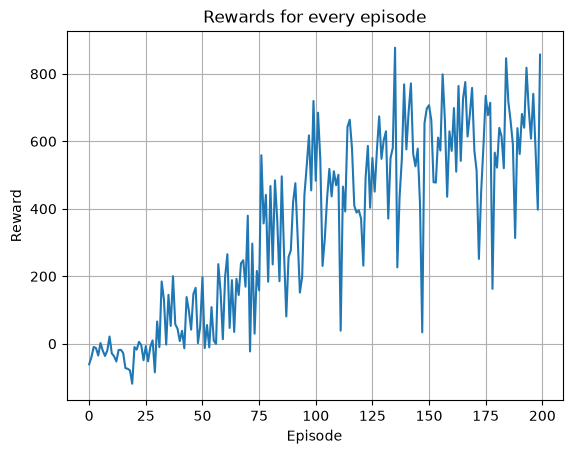

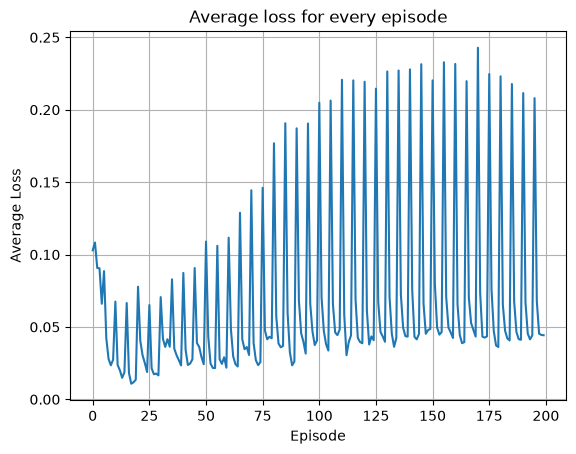

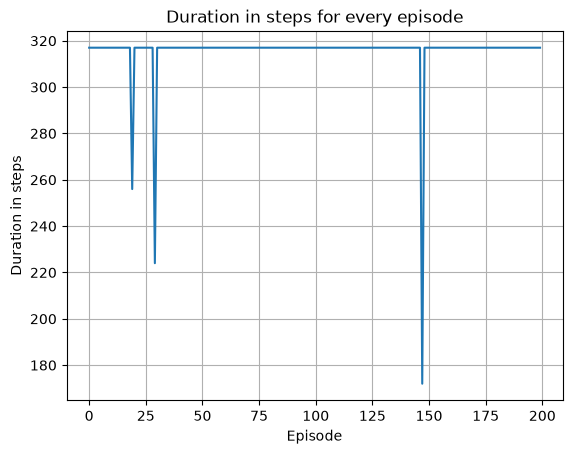

Training time on GPU in minutes: 19.931209949652352


In [60]:
simulate(EPISODES)
